In [ ]:
# %pip install --upgrade -q aif360
# %pip install -q aif360[LFR]

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [9]:
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from aif360.sklearn.datasets import fetch_adult, fetch_bank, fetch_german
from aif360.sklearn.metrics import (
    consistency_score,
    disparate_impact_ratio,
    make_scorer,
    statistical_parity_difference,
)
from aif360.sklearn.preprocessing import LearnedFairRepresentations
from sklearn import metrics as skm
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split

pd.set_option("display.max_columns", None)
SEED = 14

### 1. Datasets

I have selected the adult, german, and bank dataset

In [10]:
X_adult, y_adult, _ = fetch_adult()
X_german, y_german = fetch_german()
X_bank, y_bank = fetch_bank()

In [11]:
X_adult.index = y_adult.index = pd.MultiIndex.from_arrays(
    X_adult.index.codes, names=X_adult.index.names
)
y_adult = pd.Series(
    y_adult.factorize(sort=True)[0], index=y_adult.index, name=y_adult.name
)
X_adult = pd.get_dummies(X_adult, prefix_sep="__", drop_first=True, dtype=int)

In [12]:
X_german.index = y_german.index = pd.MultiIndex.from_arrays(
    X_german.index.codes, names=X_german.index.names
)
y_german = pd.Series(
    y_german.factorize(sort=True)[0], index=y_german.index, name=y_german.name
)
X_german = pd.get_dummies(X_german, prefix_sep="__", drop_first=True, dtype=int)

In [13]:
X_bank.index = y_bank.index = pd.MultiIndex.from_arrays(
    [X_bank.index.codes], names=X_bank.index.names
)
y_bank = pd.Series(y_bank.factorize(sort=True)[0], index=y_bank.index, name=y_bank.name)
X_bank = pd.get_dummies(X_bank, prefix_sep="__", drop_first=True, dtype=int)

### 2. Check metrics
- Demographic parity difference (DP_Diff)
- Disparate impact ratio (DIR)
- Consistency

UK protected attributes:
- age
- gender reassignment
- being married or in a civil partnership
- being pregnant or on maternity leave
- disability
- race including colour, nationality, ethnic or national origin
- religion or belief
- sex
- sexual orientation

In [ ]:
# Function to print fairness metrics for a given dataset and protected attribute
def print_fairness_metrics(X, y_true, protected, y_pred=None):
    metrics = {
        "Actual": [
            statistical_parity_difference(y_true, prot_attr=[protected]),
            disparate_impact_ratio(y_true, prot_attr=[protected]),
            consistency_score(X, y_true),
        ]
    }

    if y_pred is not None:
        metrics["Predicted"] = [
            statistical_parity_difference(y_true, y_pred, prot_attr=[protected]),
            disparate_impact_ratio(y_true, y_pred, prot_attr=[protected]),
            consistency_score(X, y_pred),
        ]

    table = pd.DataFrame(
        metrics,
        index=[
            "Statistical Parity Difference",
            "Disparate Impact Ratio",
            "Consistency Score",
        ],
    ).rename_axis("Metric")
    print(f"Protected attribute: {protected}")
    print(table.reset_index().to_string(index=False, float_format=lambda x: f"{x:.4f}"))


In [16]:
# Dataset Fairness Metrics
print("-- Adult Dataset --")
print_fairness_metrics(X_adult, y_adult, "sex")
print("\n-- German Dataset --")
print_fairness_metrics(X_german, y_german, "sex")
print("\n-- Bank Dataset --")
print_fairness_metrics(X_bank, y_bank, "age")

-- Adult Dataset --
Protected attribute: sex
                       Metric  Actual
Statistical Parity Difference -0.1989
       Disparate Impact Ratio  0.3635
            Consistency Score  0.8448

-- German Dataset --
Protected attribute: sex
                       Metric  Actual
Statistical Parity Difference -0.0748
       Disparate Impact Ratio  0.8966
            Consistency Score  0.6810

-- Bank Dataset --
Protected attribute: age
                       Metric  Actual
Statistical Parity Difference  0.2490
       Disparate Impact Ratio  3.3499
            Consistency Score  0.8555


### 3. Train Test split

We split the data with stratified sampling before doing any operations to prevent data leakage

In [9]:
# Split Adult dataset into train and test sets
X_train_adult, X_test_adult, y_train_adult, y_test_adult = train_test_split(
    X_adult, y_adult, stratify=y_adult, random_state=SEED
)

In [10]:
# Split German dataset into train and test sets
X_train_german, X_test_german, y_train_german, y_test_german = train_test_split(
    X_german, y_german, stratify=y_german, random_state=SEED
)

In [11]:
# Split Bank dataset into train and test sets
X_train_bank, X_test_bank, y_train_bank, y_test_bank = train_test_split(
    X_bank, y_bank, stratify=y_bank, random_state=SEED
)

### 4. Learning Fair Representations

In [12]:
def plot_lfr_grid_search(res):
    f, axes = plt.subplots(1, 3, squeeze=True, figsize=(24, 6))

    by_fair = res.set_index("param_fairness_weight")

    for ax, r in zip(axes, by_fair.index.unique()):
        sns.heatmap(
            by_fair.xs(r).pivot(
                index="param_reconstruct_weight",
                columns="param_target_weight",
                values="mean_test_score",
            ),
            annot=True,
            fmt=".1%",
            vmin=res.mean_test_score.min(),
            vmax=res.mean_test_score.max(),
            square=True,
            cbar=False,
            ax=ax,
        )

        ax.set_title("param_fairness_weight={}".format(r))


def discrimination(y_true, y_pred, protected):
    return abs(statistical_parity_difference(y_true, y_pred, prot_attr=protected))


def delta(
    y_true,
    y_pred,
    protected,
    use_bal_acc=False,
):
    if use_bal_acc:
        return balanced_accuracy_score(y_true, y_pred) - discrimination(
            y_true, y_pred, protected
        )
    else:
        return accuracy_score(y_true, y_pred) - discrimination(
            y_true, y_pred, protected
        )


def lfr_grid_search(X_train, y_train, protected):
    min_disc = make_scorer(statistical_parity_difference, prot_attr=protected)
    max_delta = skm.make_scorer(delta, protected=protected, use_bal_acc=True)

    lfr = LearnedFairRepresentations(
        protected, n_prototypes=25, max_iter=100, random_state=SEED
    )
    params = {
        "reconstruct_weight": [1e-2, 1e-3, 1e-4],
        "target_weight": [100, 1000],
        "fairness_weight": [0, 100, 1000],
    }
    grid = GridSearchCV(lfr, params, scoring=max_delta, cv=3, n_jobs=-1).fit(
        X_train, y_train
    )

    plot_lfr_grid_search(pd.DataFrame(grid.cv_results_))

    return grid

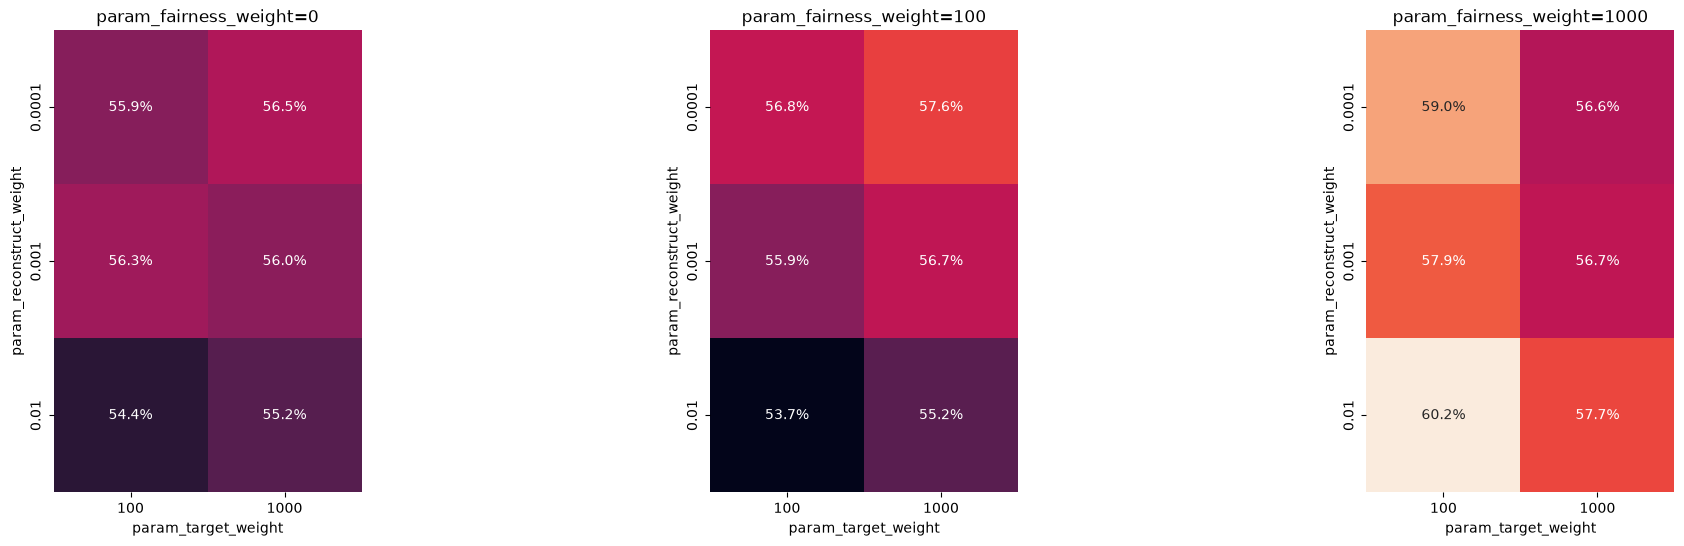

In [13]:
adult_grid = lfr_grid_search(X_train_adult, y_train_adult, "sex")

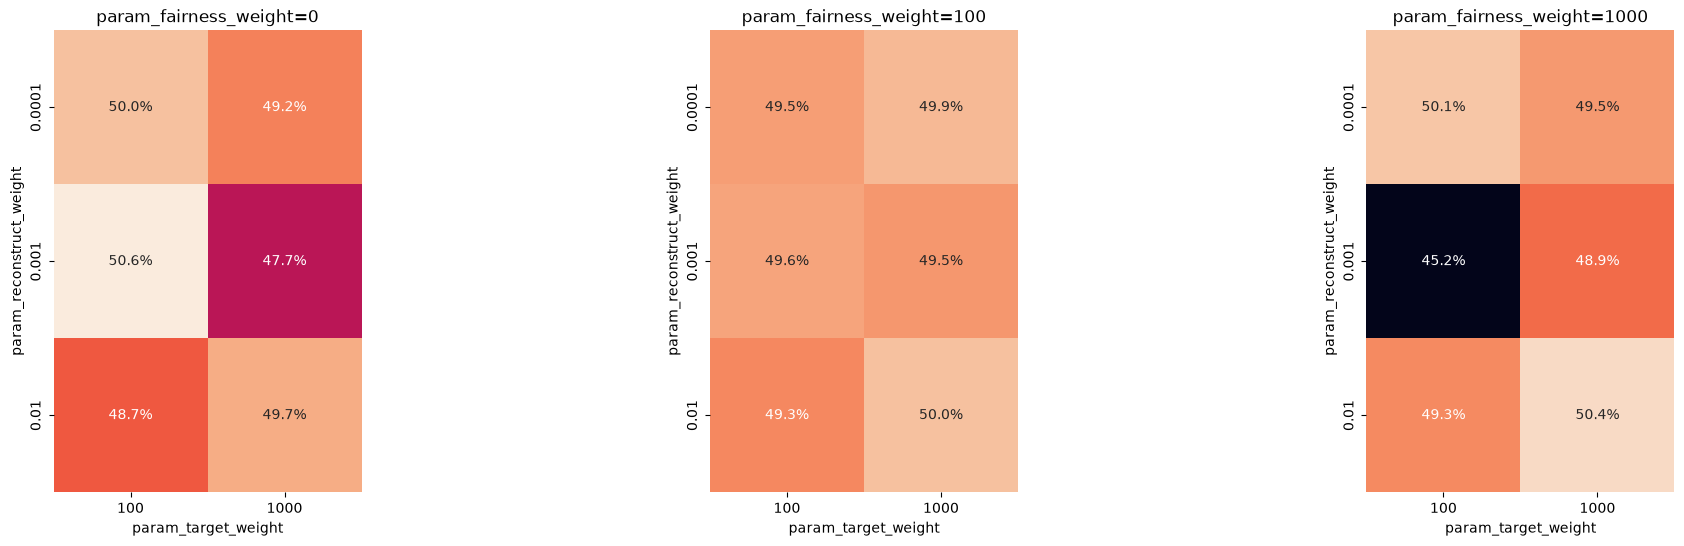

In [14]:
german_grid = lfr_grid_search(X_train_german, y_train_german, "sex")

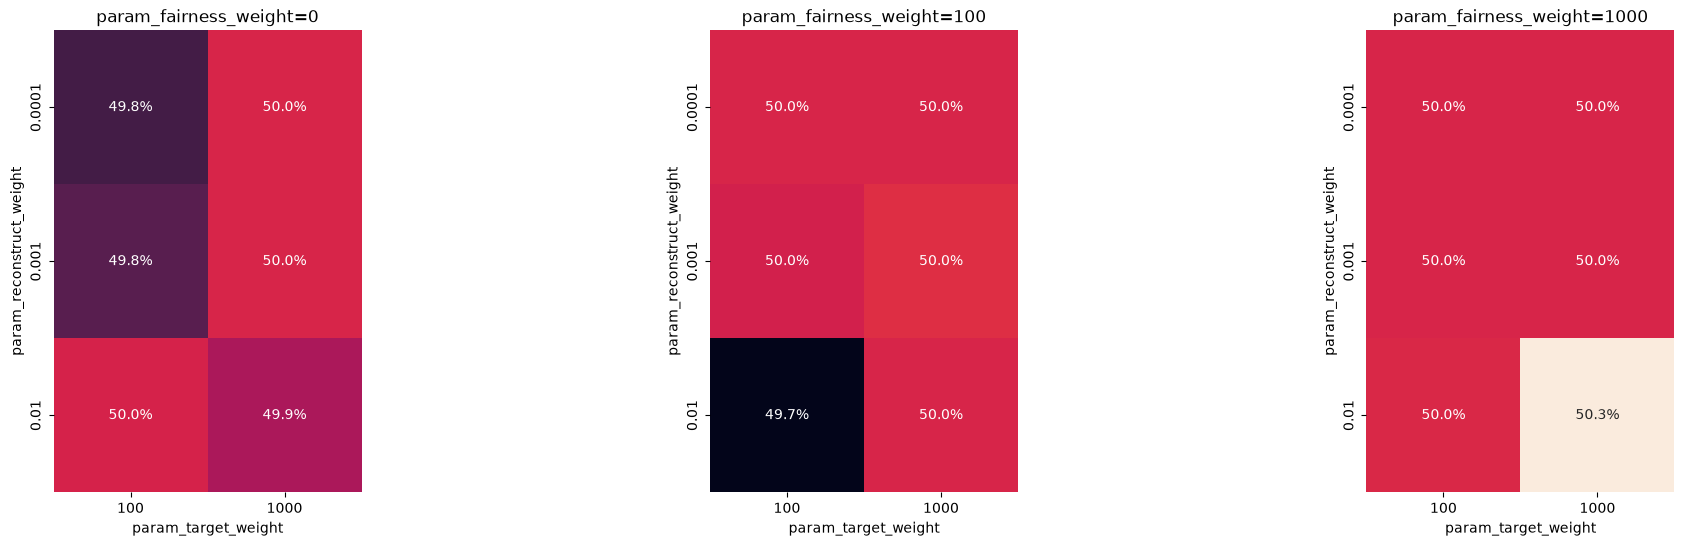

In [15]:
bank_grid = lfr_grid_search(X_train_bank, y_train_bank, "age")

### 5. Logistic regression classification

In [16]:
def evaluate(model, grid, protected, X_train, y_train, X_test, y_test):
    y_pred = model.fit(X_train, y_train).predict(X_test)
    y_pred_lfr = model.fit(grid.transform(X_train), y_train).predict(X_test)
    results = classification_report(y_test, y_pred, output_dict=True)
    results_lfr = classification_report(y_test, y_pred_lfr, output_dict=True)

    print("Evaluation results without LFR:")
    print(f"f1-score, {protected} 0: {results['0']['f1-score']}")
    print(f"f1-score, {protected} 1: {results['1']['f1-score']}\n")
    print_fairness_metrics(X_test, y_test, protected, y_pred=y_pred)

    print("\nEvaluation results with LFR:")
    print(f"f1-score, {protected} 0: {results_lfr['0']['f1-score']}")
    print(f"f1-score, {protected} 1: {results_lfr['1']['f1-score']}\n")
    print_fairness_metrics(X_test, y_test, protected, y_pred=y_pred_lfr)


lr = LogisticRegression(solver="lbfgs", random_state=SEED)


In [17]:
print("Adult Dataset")
evaluate(
    lr, adult_grid, "sex", X_train_adult, y_train_adult, X_test_adult, y_test_adult
)

Adult Dataset
Evaluation results without LFR:
f1-score, sex 0: 0.8934914600238325
f1-score, sex 1: 0.6237722990579274

Protected attribute: sex
                       Metric  Actual  Predicted
Statistical Parity Difference -0.2093    -0.1866
       Disparate Impact Ratio  0.3377     0.2659
            Consistency Score  0.8399     0.9231

Evaluation results with LFR:
f1-score, sex 0: 0.3196059113300493
f1-score, sex 1: 0.44583533943187287

Protected attribute: sex
                       Metric  Actual  Predicted
Statistical Parity Difference -0.2093    -0.1199
       Disparate Impact Ratio  0.3377     0.8658
            Consistency Score  0.8399     0.9762


In [18]:
print("German Dataset")
evaluate(
    lr, german_grid, "sex", X_train_german, y_train_german, X_test_german, y_test_german
)

German Dataset
Evaluation results without LFR:
f1-score, sex 0: 0.5611510791366906
f1-score, sex 1: 0.8310249307479224

Protected attribute: sex
                       Metric  Actual  Predicted
Statistical Parity Difference -0.0624    -0.1647
       Disparate Impact Ratio  0.9135     0.7941
            Consistency Score  0.6936     0.7072

Evaluation results with LFR:
f1-score, sex 0: 0.4520547945205479
f1-score, sex 1: 0.23076923076923078

Protected attribute: sex
                       Metric  Actual  Predicted
Statistical Parity Difference -0.0624     0.1030
       Disparate Impact Ratio  0.9135     2.0625
            Consistency Score  0.6936     0.9664


In [19]:
print("Bank Dataset")
evaluate(lr, bank_grid, "age", X_train_bank, y_train_bank, X_test_bank, y_test_bank)

Bank Dataset
Evaluation results without LFR:
f1-score, age 0: 0.9385390665473555
f1-score, age 1: 0.049526584122359794

Protected attribute: age
                       Metric  Actual  Predicted
Statistical Parity Difference  0.2738     0.0073
       Disparate Impact Ratio  3.6239     2.7593
            Consistency Score  0.8498     0.9947

Evaluation results with LFR:
f1-score, age 0: 0.40434680634821357
f1-score, age 1: 0.22373917473255223

Protected attribute: age
                       Metric  Actual  Predicted
Statistical Parity Difference  0.2738     0.0373
       Disparate Impact Ratio  3.6239     1.0497
            Consistency Score  0.8498     0.9474
